# Model Comparison — CIC-IDS-2018

So sánh 6 kiến trúc detector trên **cùng test split** (`test_binary.csv`):

| # | Model | Loại | Unsupervised component | Supervised component |
|---|---|---|---|---|
| 1 | **Autoencoder only** | One-class | AE reconstruction error | — |
| 2 | **AE + XGBoost OR-Fusion** | Hybrid | AE reconstruction error | XGBoost (aug features) |
| 3 | **MixtureSVDD + XGBoost OR-Fusion** | Hybrid | Deep SVDD d_min | XGBoost |
| 4 | **CLAD** | Contrastive | Cosine sim to benign centroid | — |

**Metrics:** AUC-ROC, AUC-PR, F1, Recall, Precision, FPR, FPR@95TPR, Zero-shot Recall, Inference latency

**Threshold rule:** tune trên `val_binary.csv` (PR-curve max F1), áp dụng unchanged lên `test_binary.csv`.

## CELL 1 — Imports & Config

In [1]:
import sys, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

import joblib
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_recall_curve, roc_curve,
    f1_score, recall_score, precision_score,
    confusion_matrix, classification_report,
)


#   ĐỔI DATASET                  
#                                                                   
#   v0 Slowloris    : DATA_DIR      = 'binary_split_zeroshot_dataset'    
#                     ZEROSHOT_FILE = 'DoS attacks-Slowloris.csv'        
#                     ZEROSHOT_LABEL= 'DoS Slowloris'                    
#                     ARTIFACT_SUFFIX = '_v0_slowloris'                  
#                                                                   
#   v1 Infilteration: DATA_DIR      = 'binary_split_dataset_z_Infilteration' 
#                     ZEROSHOT_FILE = 'Infilteration.csv'               
#                     ZEROSHOT_LABEL= 'Infilteration'                   
#                     ARTIFACT_SUFFIX = '_v1_infilteration'             


DATA_DIR        = 'binary_split_dataset_z_Infilteration'
ZEROSHOT_FILE   = 'Infilteration.csv'
ZEROSHOT_LABEL  = 'Infilteration'
ARTIFACT_SUFFIX = '_v1_infilteration'


REPO_ROOT   = os.path.abspath('..')          
DATA_PATH   = os.path.join(REPO_ROOT, DATA_DIR)

# Autoencoder (dùng chung, không đổi theo dataset)
AE_CKPT_DIR = os.path.join(REPO_ROOT, 'AE_XGBoost', 'checkpoints')
AE_CKPT     = os.path.join(AE_CKPT_DIR, 'ae_best.pt')
AE_SCALER   = os.path.join(AE_CKPT_DIR, 'scaler_ae.pkl')
XGB_AUG     = os.path.join(AE_CKPT_DIR, 'xgb_aug_model.pkl')

# SVDD-Augmented XGBoost (feature augmentation - K sphere distances + d_min)
SVDD_CKPT_DIR = os.path.join(REPO_ROOT, 'SVDD_XGBoost', 'checkpoints')
SVDD_DIR    = os.path.join(SVDD_CKPT_DIR, f'svdd_model{ARTIFACT_SUFFIX}')
SVDD_SCALER = os.path.join(SVDD_CKPT_DIR, f'scaler_svdd{ARTIFACT_SUFFIX}.pkl')
XGB_SVDD    = os.path.join(SVDD_CKPT_DIR, f'xgb_svdd_model{ARTIFACT_SUFFIX}.pkl')

# CLAD checkpoint (theo ARTIFACT_SUFFIX nếu có, fallback về best.pt)
_clad_suffix = os.path.join(REPO_ROOT, 'clad', 'checkpoints', f'best{ARTIFACT_SUFFIX}.pt')
CLAD_CKPT   = _clad_suffix if os.path.exists(_clad_suffix) else \
              os.path.join(REPO_ROOT, 'clad', 'checkpoints', 'best.pt')

sys.path.insert(0, REPO_ROOT)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED   = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

CLIP_VAL = 20.0

print(f'Device         : {DEVICE}')
print(f'Repo root      : {REPO_ROOT}')
print(f'Dataset        : {DATA_DIR}')
print(f'Zero-shot      : {ZEROSHOT_FILE}  ({ZEROSHOT_LABEL})')
print(f'Artifact suffix: {ARTIFACT_SUFFIX}')
print()

# Check which checkpoints exist
for label, path in [
    ('AE checkpoint',           AE_CKPT),
    ('AE scaler',               AE_SCALER),
    ('XGB-aug model',           XGB_AUG),
    ('SVDD model dir',          SVDD_DIR),
    ('SVDD scaler',             SVDD_SCALER),
    ('XGB-SVDD-Aug model',      XGB_SVDD),
    ('CLAD checkpoint',         CLAD_CKPT),
]:
    status = '✓' if os.path.exists(path) else '✗ MISSING'
    print(f'  [{status}] {label}: {path}')

Device         : cuda
Repo root      : d:\UTS_RS\workspace\UTS_Layer1
Dataset        : binary_split_dataset_z_Infilteration
Zero-shot      : Infilteration.csv  (Infilteration)
Artifact suffix: _v1_infilteration

  [✓] AE checkpoint: d:\UTS_RS\workspace\UTS_Layer1\AE_XGBoost\checkpoints\ae_best.pt
  [✓] AE scaler: d:\UTS_RS\workspace\UTS_Layer1\AE_XGBoost\checkpoints\scaler_ae.pkl
  [✓] XGB-aug model: d:\UTS_RS\workspace\UTS_Layer1\AE_XGBoost\checkpoints\xgb_aug_model.pkl
  [✓] SVDD model dir: d:\UTS_RS\workspace\UTS_Layer1\SVDD_XGBoost\checkpoints\svdd_model_v1_infilteration
  [✓] SVDD scaler: d:\UTS_RS\workspace\UTS_Layer1\SVDD_XGBoost\checkpoints\scaler_svdd_v1_infilteration.pkl
  [✓] XGB-SVDD-Aug model: d:\UTS_RS\workspace\UTS_Layer1\SVDD_XGBoost\checkpoints\xgb_svdd_model_v1_infilteration.pkl
  [✓] CLAD checkpoint: d:\UTS_RS\workspace\UTS_Layer1\clad\checkpoints\best.pt


## CELL 2 — Feature List & Data Loading

In [2]:
FEATURES = [
    'Dst Port', 'Protocol', 'Flow Duration', 'Tot Fwd Pkts',
    'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max',
    'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std', 'Bwd Pkt Len Max',
    'Bwd Pkt Len Min', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Flow Byts/s',
    'Flow Pkts/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
    'Fwd IAT Tot', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min',
    'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min',
    'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags',
    'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s', 'Bwd Pkts/s',
    'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean', 'Pkt Len Std', 'Pkt Len Var',
    'FIN Flag Cnt', 'SYN Flag Cnt', 'RST Flag Cnt', 'PSH Flag Cnt',
    'ACK Flag Cnt', 'URG Flag Cnt', 'CWE Flag Count', 'ECE Flag Cnt',
    'Down/Up Ratio', 'Pkt Size Avg', 'Fwd Seg Size Avg', 'Bwd Seg Size Avg',
    'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg',
    'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg', 'Subflow Fwd Pkts', 'Subflow Fwd Byts',
    'Subflow Bwd Pkts', 'Subflow Bwd Byts', 'Init Fwd Win Byts',
    'Init Bwd Win Byts', 'Fwd Act Data Pkts', 'Fwd Seg Size Min',
    'Active Mean', 'Active Std', 'Active Max', 'Active Min',
    'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min',
]
DTYPE_DICT = {f: 'float32' for f in FEATURES}
DTYPE_DICT['Label'] = 'int8'

print('Loading data...')
train_benign_df = pd.read_csv(
    os.path.join(DATA_PATH, 'train_isolation_benign.csv'),
    usecols=FEATURES + ['Label'], dtype=DTYPE_DICT)
train_binary_df = pd.read_csv(
    os.path.join(DATA_PATH, 'train_xgboost_binary.csv'),
    usecols=FEATURES + ['Label'], dtype=DTYPE_DICT)
val_df  = pd.read_csv(os.path.join(DATA_PATH, 'val_binary.csv'),
                      usecols=FEATURES + ['Label'], dtype=DTYPE_DICT)
test_df = pd.read_csv(os.path.join(DATA_PATH, 'test_binary.csv'),
                      usecols=FEATURES + ['Label'], dtype=DTYPE_DICT)
# Zero-shot file co the chua duplicate-header rows (gia tri 'Dst Port' lap lai
# trong du lieu) -> doc dang string truoc, loc bo, roi moi ep kieu.
zero_df = pd.read_csv(os.path.join(DATA_PATH, ZEROSHOT_FILE),
                      usecols=FEATURES, dtype=str)
zero_df = zero_df[zero_df['Dst Port'] != 'Dst Port'].copy()
zero_df = zero_df.astype({f: 'float32' for f in FEATURES})

X_val   = val_df[FEATURES].values.copy();   y_val   = val_df['Label'].values.astype(int)
X_test  = test_df[FEATURES].values.copy();  y_test  = test_df['Label'].values.astype(int)
ZEROSHOT_N = None  # None = lấy toàn bộ; đổi số này để thay đổi sample size
if ZEROSHOT_N is not None:
    zero_df = zero_df.head(ZEROSHOT_N)
X_zero  = zero_df[FEATURES].values.copy();  y_zero  = np.ones(len(zero_df), dtype=int)
X_train_benign = train_benign_df[FEATURES].values.copy()
X_train_binary = train_binary_df[FEATURES].values.copy()
y_train_binary = train_binary_df['Label'].values.astype(int)

# Replace inf/nan
for X in (X_train_benign, X_train_binary, X_val, X_test, X_zero):
    X[~np.isfinite(X)] = np.nan
col_means = np.nanmean(X_train_benign, axis=0)
for X in (X_train_benign, X_train_binary, X_val, X_test, X_zero):
    nan_mask = np.isnan(X)
    X[nan_mask] = np.take(col_means, np.where(nan_mask)[1])

print(f'Val  : {len(y_val):,}  (benign={(y_val==0).sum():,}  attack={(y_val==1).sum():,})')
print(f'Test : {len(y_test):,}  (benign={(y_test==0).sum():,}  attack={(y_test==1).sum():,})')
print(f'Zero : {len(y_zero):,}  (all attack — {ZEROSHOT_LABEL})')

Loading data...
Val  : 303,855  (benign=243,084  attack=60,771)
Test : 303,900  (benign=243,120  attack=60,780)
Zero : 161,934  (all attack — Infilteration)


## CELL 3 — Shared Utilities

In [3]:
def best_f1_threshold(y_true, scores):
    """PR-curve F1 optimisation — tune on val only."""
    prec, rec, thr = precision_recall_curve(y_true, scores)
    f1 = 2 * prec * rec / (prec + rec + 1e-8)
    idx = np.argmax(f1)
    return thr[min(idx, len(thr)-1)], f1[idx], prec[idx], rec[idx]


def fpr_at_recall(y_true, scores, target=0.95):
    fpr, tpr, _ = roc_curve(y_true, scores)
    idx = np.searchsorted(tpr, target)
    return float(fpr[min(idx, len(fpr)-1)])


def full_eval(name, y_true, scores, threshold, y_zero=None, zero_scores=None):
    """Compute all metrics. Returns dict."""
    y_pred  = (scores >= threshold).astype(int)
    auc_roc = roc_auc_score(y_true, scores)
    auc_pr  = average_precision_score(y_true, scores)
    fpr95   = fpr_at_recall(y_true, scores)
    f1      = f1_score(y_true, y_pred, zero_division=0)
    rec     = recall_score(y_true, y_pred, zero_division=0)
    prec    = precision_score(y_true, y_pred, zero_division=0)
    cm      = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (cm[0,0], 0, 0, 0)
    fpr_val = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    zero_recall = None
    if zero_scores is not None and y_zero is not None:
        zero_pred   = (zero_scores >= threshold).astype(int)
        zero_recall = zero_pred.mean()

    return {
        'name': name,
        'auc_roc': auc_roc, 'auc_pr': auc_pr,
        'fpr95': fpr95,
        'f1': f1, 'recall': rec, 'precision': prec, 'fpr': fpr_val,
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        'zero_recall': zero_recall,
        'threshold': threshold,
        'scores': scores,           # keep for plots
        'y_pred': y_pred,
    }


def print_result(r):
    print(f"\n{'='*55}")
    print(f"  {r['name']}")
    print(f"{'='*55}")
    print(f"  AUC-ROC  : {r['auc_roc']:.4f}")
    print(f"  AUC-PR   : {r['auc_pr']:.4f}")
    print(f"  FPR@95R  : {r['fpr95']:.4f}")
    print(f"  F1       : {r['f1']:.4f}")
    print(f"  Recall   : {r['recall']:.4f}")
    print(f"  Precision: {r['precision']:.4f}")
    print(f"  FPR      : {r['fpr']:.4f}")
    print(f"  TN={r['tn']:,}  FP={r['fp']:,}  FN={r['fn']:,}  TP={r['tp']:,}")
    if r['zero_recall'] is not None:
        print(f"  Zero-shot Recall: {r['zero_recall']:.4f}  ({r['zero_recall']*100:.1f}%)")


results = {}   # populated by each model section
print('Utilities defined.')

Utilities defined.


## CELL 4 — Autoencoder Model Definition

In [4]:
class BenignAutoencoder(nn.Module):
    def __init__(self, input_dim=78, bottleneck_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64), nn.LayerNorm(64), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(64, 32),        nn.LayerNorm(32), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(32, bottleneck_dim), nn.LayerNorm(bottleneck_dim), nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_dim, 32), nn.LayerNorm(32), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(32, 64),             nn.LayerNorm(64), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(64, input_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

    def reconstruction_error(self, x):
        x_hat, _ = self.forward(x)
        return ((x - x_hat) ** 2).mean(dim=1)


def get_ae_scores(model, X_np, batch_size=4096):
    model.eval()
    loader = DataLoader(TensorDataset(torch.tensor(X_np, dtype=torch.float32)),
                        batch_size=batch_size, shuffle=False)
    errs = []
    with torch.no_grad():
        for (xb,) in loader:
            errs.append(model.reconstruction_error(xb.to(DEVICE)).cpu().numpy())
    return np.concatenate(errs)


def get_ae_latent(model, X_np, batch_size=4096):
    model.eval()
    loader = DataLoader(TensorDataset(torch.tensor(X_np, dtype=torch.float32)),
                        batch_size=batch_size, shuffle=False)
    zs = []
    with torch.no_grad():
        for (xb,) in loader:
            _, z = model(xb.to(DEVICE))
            zs.append(z.cpu().numpy())
    return np.concatenate(zs)


print('AE class defined.')

AE class defined.


## CELL 5 — Load & Preprocess for AE / AE+XGBoost

In [5]:
from sklearn.preprocessing import RobustScaler

# Load AE scaler (fit on benign train)
ae_scaler = joblib.load(AE_SCALER)
X_val_ae  = np.clip(ae_scaler.transform(X_val),  -CLIP_VAL, CLIP_VAL)
X_test_ae = np.clip(ae_scaler.transform(X_test), -CLIP_VAL, CLIP_VAL)
X_zero_ae = np.clip(ae_scaler.transform(X_zero), -CLIP_VAL, CLIP_VAL)
print(f'AE scaler loaded: mean={ae_scaler.center_.mean():.4f}')

# Load AE model
ae_model = BenignAutoencoder(input_dim=len(FEATURES), bottleneck_dim=16).to(DEVICE)
ae_model.load_state_dict(torch.load(AE_CKPT, map_location=DEVICE))
ae_model.eval()
print('AE checkpoint loaded.')

# Compute reconstruction errors
print('Computing AE scores...')
ae_err_val  = get_ae_scores(ae_model, X_val_ae)
ae_err_test = get_ae_scores(ae_model, X_test_ae)
ae_err_zero = get_ae_scores(ae_model, X_zero_ae)

ae_min = ae_err_val.min()
ae_max = ae_err_val.max()
ae_norm_val  = (ae_err_val  - ae_min) / (ae_max - ae_min + 1e-9)
ae_norm_test = (ae_err_test - ae_min) / (ae_max - ae_min + 1e-9)
ae_norm_zero = (ae_err_zero - ae_min) / (ae_max - ae_min + 1e-9)

print(f'AE val   — benign mean err: {ae_err_val[y_val==0].mean():.4f}')
print(f'AE val   — attack mean err: {ae_err_val[y_val==1].mean():.4f}')
print(f'AE test  — benign mean err: {ae_err_test[y_test==0].mean():.4f}')
print(f'AE test  — attack mean err: {ae_err_test[y_test==1].mean():.4f}')

AE scaler loaded: mean=305.5252
AE checkpoint loaded.
Computing AE scores...
AE val   — benign mean err: 0.7321
AE val   — attack mean err: 3.3615
AE test  — benign mean err: 0.7286
AE test  — attack mean err: 3.3866


## CELL 6 — Model 1: Autoencoder Only

In [6]:
# Fixed threshold = 0.5 (consistent across all models for fair comparison)
thr_ae = 0.5
print(f'AE threshold (fixed): {thr_ae:.2f}')

res_ae = full_eval(
    'Autoencoder Only',
    y_test, ae_err_test, thr_ae,
    y_zero, ae_err_zero,
)
results['AE Only'] = res_ae
print_result(res_ae)

AE threshold (fixed): 0.50

  Autoencoder Only
  AUC-ROC  : 0.8495
  AUC-PR   : 0.5648
  FPR@95R  : 0.6589
  F1       : 0.5771
  Recall   : 0.8541
  Precision: 0.4357
  FPR      : 0.2765
  TN=175,895  FP=67,225  FN=8,866  TP=51,914
  Zero-shot Recall: 0.3484  (34.8%)


## CELL 7 — Model 2: AE-Augmented XGBoost

AE chỉ đóng vai trò **feature encoder** (latent_z + reconstruction_error nối vào 78 feature gốc).
XGBoost là điểm quyết định duy nhất — không có ngưỡng AE riêng, không OR-Fusion.

In [7]:
import xgboost as xgb

xgb_aug = joblib.load(XGB_AUG)
print('XGB-aug model loaded.')

BOTTLENECK_DIM = 16

# Build augmented features: [original | latent_z | recon_error]
print('Computing augmented features...')
ae_latent_val  = get_ae_latent(ae_model, X_val_ae)
ae_latent_test = get_ae_latent(ae_model, X_test_ae)
ae_latent_zero = get_ae_latent(ae_model, X_zero_ae)

X_aug_val  = np.concatenate([X_val_ae,  ae_latent_val,  ae_err_val.reshape(-1,1)],  axis=1)
X_aug_test = np.concatenate([X_test_ae, ae_latent_test, ae_err_test.reshape(-1,1)], axis=1)
X_aug_zero = np.concatenate([X_zero_ae, ae_latent_zero, ae_err_zero.reshape(-1,1)], axis=1)

xgb_aug_proba_val  = xgb_aug.predict_proba(X_aug_val)[:, 1]
xgb_aug_proba_test = xgb_aug.predict_proba(X_aug_test)[:, 1]
xgb_aug_proba_zero = xgb_aug.predict_proba(X_aug_zero)[:, 1]

# Fixed threshold = 0.5 (consistent across all models for fair comparison).
# AE never gets its own threshold; XGBoost alone decides using the
# latent/recon_error signal it learned during training.
thr_ae_xgb = 0.5
print(f'AE-Aug XGBoost threshold (fixed): {thr_ae_xgb:.2f}')

res_ae_xgb = full_eval(
    'AE + XGBoost',
    y_test, xgb_aug_proba_test, thr_ae_xgb,
    y_zero, xgb_aug_proba_zero,
)
results['AE + XGBoost'] = res_ae_xgb
print_result(res_ae_xgb)

XGB-aug model loaded.
Computing augmented features...
AE-Aug XGBoost threshold (fixed): 0.50

  AE + XGBoost
  AUC-ROC  : 1.0000
  AUC-PR   : 0.9999
  FPR@95R  : 0.0001
  F1       : 0.9940
  Recall   : 0.9984
  Precision: 0.9896
  FPR      : 0.0026
  TN=242,480  FP=640  FN=96  TP=60,684
  Zero-shot Recall: 0.0078  (0.8%)


## CELL 8 — SVDD Model Definition

In [8]:
class SVDDEncoder(nn.Module):
    def __init__(self, input_dim=78, embed_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256), nn.LayerNorm(256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128),       nn.LayerNorm(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, embed_dim, bias=False),
        )
    def forward(self, x):
        return F.normalize(self.net(x), dim=1)


class MixtureSVDD:
    def __init__(self, K, input_dim=78, embed_dim=64, device='cpu'):
        self.K        = K
        self.device   = device
        self.encoders = [SVDDEncoder(input_dim, embed_dim).to(device) for _ in range(K)]
        self.centers  = [None] * K
        self.radii    = [None] * K

    def all_sphere_distances(self, X_np, batch_size=4096):
        X_t    = torch.tensor(X_np, dtype=torch.float32)
        loader = DataLoader(TensorDataset(X_t), batch_size=batch_size, shuffle=False)
        all_dists = []
        for k in range(self.K):
            self.encoders[k].eval()
            c = self.centers[k]
            dists_k = []
            with torch.no_grad():
                for (xb,) in loader:
                    z = self.encoders[k](xb.to(self.device))
                    dists_k.append(((z - c) ** 2).sum(dim=1).cpu().numpy())
            all_dists.append(np.concatenate(dists_k))
        return np.stack(all_dists, axis=1)  # [n_samples, K]

    def decision_scores(self, X_np, batch_size=4096):
        return self.all_sphere_distances(X_np, batch_size=batch_size).min(axis=1)

    def load(self, path):
        centers_np = np.load(os.path.join(path, 'centers.npy'), allow_pickle=True)
        self.radii  = list(np.load(os.path.join(path, 'radii.npy'), allow_pickle=True))
        for k, enc in enumerate(self.encoders):
            enc.load_state_dict(
                torch.load(os.path.join(path, f'encoder_{k}.pt'), map_location=self.device))
            self.centers[k] = torch.tensor(centers_np[k], dtype=torch.float32).to(self.device)
        print(f'SVDD loaded ({self.K} spheres) from {path}')


print('SVDD class defined.')

SVDD class defined.


## CELL 9 — Load & Preprocess for SVDD / SVDD+XGBoost

In [9]:
# Load SVDD scaler
svdd_scaler = joblib.load(SVDD_SCALER)
X_val_svdd  = np.clip(svdd_scaler.transform(X_val),  -CLIP_VAL, CLIP_VAL)
X_test_svdd = np.clip(svdd_scaler.transform(X_test), -CLIP_VAL, CLIP_VAL)
X_zero_svdd = np.clip(svdd_scaler.transform(X_zero), -CLIP_VAL, CLIP_VAL)
print('SVDD scaler loaded.')

# Count how many spheres were saved
n_spheres = sum(1 for f in os.listdir(SVDD_DIR) if f.startswith('encoder_'))
print(f'Detected {n_spheres} SVDD spheres.')

svdd = MixtureSVDD(K=n_spheres, input_dim=len(FEATURES), embed_dim=64, device=str(DEVICE))
svdd.load(SVDD_DIR)

print('Computing SVDD scores...')
svdd_scores_val  = svdd.decision_scores(X_val_svdd)
svdd_scores_test = svdd.decision_scores(X_test_svdd)
svdd_scores_zero = svdd.decision_scores(X_zero_svdd)

svdd_min = svdd_scores_val.min()
svdd_max = svdd_scores_val.max()
svdd_norm_val  = (svdd_scores_val  - svdd_min) / (svdd_max - svdd_min + 1e-9)
svdd_norm_test = (svdd_scores_test - svdd_min) / (svdd_max - svdd_min + 1e-9)
svdd_norm_zero = (svdd_scores_zero - svdd_min) / (svdd_max - svdd_min + 1e-9)
print('SVDD scores computed.')

SVDD scaler loaded.
Detected 10 SVDD spheres.
SVDD loaded (10 spheres) from d:\UTS_RS\workspace\UTS_Layer1\SVDD_XGBoost\checkpoints\svdd_model_v1_infilteration
Computing SVDD scores...
SVDD scores computed.


## CELL 10 — Model 3: MixtureSVDD Only

In [10]:
thr_svdd = 0.5
print(f'SVDD threshold (fixed): {thr_svdd:.2f}')

res_svdd = full_eval(
    'MixtureSVDD Only',
    y_test, svdd_scores_test, thr_svdd,
    y_zero, svdd_scores_zero,
)
results['SVDD Only'] = res_svdd
print_result(res_svdd)

SVDD threshold (fixed): 0.50

  MixtureSVDD Only
  AUC-ROC  : 0.7554
  AUC-PR   : 0.4724
  FPR@95R  : 0.6298
  F1       : 0.0000
  Recall   : 0.0000
  Precision: 0.0000
  FPR      : 0.0000
  TN=243,120  FP=0  FN=60,780  TP=0
  Zero-shot Recall: 0.0000  (0.0%)


## CELL 10b — Model 4: SVDD-Augmented XGBoost (K sphere distances + d_min as features)

In [11]:
XGB_SVDD_AVAILABLE = os.path.exists(XGB_SVDD)
print(f'XGB-SVDD-Aug model: {"FOUND" if XGB_SVDD_AVAILABLE else "NOT FOUND — chay svdd_xgboost_ids.ipynb truoc"}')

if XGB_SVDD_AVAILABLE:
    xgb_svdd = joblib.load(XGB_SVDD)
    print(f'Loaded: {XGB_SVDD}')

    # K sphere distances (da tinh o Cell 9) + d_min -> augmented feature matrix
    svdd_dists_val  = svdd.all_sphere_distances(X_val_svdd)
    svdd_dists_test = svdd.all_sphere_distances(X_test_svdd)
    svdd_dists_zero = svdd.all_sphere_distances(X_zero_svdd)

    X_val_aug_svdd  = np.concatenate([X_val_svdd,  svdd_dists_val,  svdd_dists_val.min(axis=1, keepdims=True)], axis=1)
    X_test_aug_svdd = np.concatenate([X_test_svdd, svdd_dists_test, svdd_dists_test.min(axis=1, keepdims=True)], axis=1)
    X_zero_aug_svdd = np.concatenate([X_zero_svdd, svdd_dists_zero, svdd_dists_zero.min(axis=1, keepdims=True)], axis=1)

    xgb_svdd_proba_val  = xgb_svdd.predict_proba(X_val_aug_svdd)[:, 1]
    xgb_svdd_proba_test = xgb_svdd.predict_proba(X_test_aug_svdd)[:, 1]
    xgb_svdd_proba_zero = xgb_svdd.predict_proba(X_zero_aug_svdd)[:, 1]

    thr_svdd_aug = 0.5
    print(f'SVDD-Aug XGBoost threshold (fixed): {thr_svdd_aug:.2f}')

    res_svdd_aug = full_eval(
        'SVDD-Aug XGBoost',
        y_test, xgb_svdd_proba_test, thr_svdd_aug,
        y_zero, xgb_svdd_proba_zero,
    )
    results['SVDD-Aug XGBoost'] = res_svdd_aug
    print_result(res_svdd_aug)
else:
    print('SVDD-Aug XGBoost skipped. Chay svdd_xgboost_ids.ipynb de tao artifact.')
    results['SVDD-Aug XGBoost'] = {
        'name': 'SVDD-Aug XGBoost — not trained',
        'auc_roc': None, 'auc_pr': None, 'fpr95': None,
        'f1': None, 'recall': None, 'precision': None, 'fpr': None,
        'tn': None, 'fp': None, 'fn': None, 'tp': None,
        'zero_recall': None, 'threshold': None,
        'scores': None, 'y_pred': None,
    }

XGB-SVDD-Aug model: FOUND
Loaded: d:\UTS_RS\workspace\UTS_Layer1\SVDD_XGBoost\checkpoints\xgb_svdd_model_v1_infilteration.pkl
SVDD-Aug XGBoost threshold (fixed): 0.50

  SVDD-Aug XGBoost
  AUC-ROC  : 0.9999
  AUC-PR   : 0.9996
  FPR@95R  : 0.0002
  F1       : 0.9948
  Recall   : 0.9984
  Precision: 0.9911
  FPR      : 0.0022
  TN=242,575  FP=545  FN=95  TP=60,685
  Zero-shot Recall: 0.0105  (1.1%)


## CELL 12 — Model 5: CLAD
> Cell này tự động **skip** nếu `closr/checkpoints/best.pt` chưa tồn tại.  
> Chạy `python closr/train.py --data_dir binary_split_zeroshot_dataset --epochs 200` để tạo checkpoint.

In [12]:
CLAD_AVAILABLE = os.path.exists(CLAD_CKPT)
print(f'CLAD checkpoint: {"FOUND" if CLAD_AVAILABLE else "NOT FOUND — skipping"}')

if CLAD_AVAILABLE:
    from clad.model           import build_model
    from clad.util.checkpoint import load_checkpoint
    from clad.util.distance   import get_features, get_centroid, cosine_scores_to_centroid
    from clad.data.dataset    import load_splits, make_eval_loader, ZNormaliser

    # CLAD uses its own ZNormaliser fit on benign-only rows of training set
    # We refit here on X_train_benign scaled the same way as closr/data/dataset.py
    X_train_b = X_train_benign.copy()
    clad_norm = ZNormaliser().fit(X_train_b)
    X_val_clad  = clad_norm.transform(X_val.copy())
    X_test_clad = clad_norm.transform(X_test.copy())
    X_zero_clad = clad_norm.transform(X_zero.copy())

    # Load model
    clad_model = build_model(d_in=len(FEATURES), hidden_dim=512, n_layers=4, d_out=32).to(DEVICE)
    epoch_ckpt, saved = load_checkpoint(CLAD_CKPT, clad_model, device=str(DEVICE))
    print(f'CLAD checkpoint epoch={epoch_ckpt}  saved metrics={saved}')

    # Centroid — load from checkpoint if saved, else recompute
    if 'centroid' in saved:
        centroid = torch.tensor(saved['centroid'], dtype=torch.float32)
        print('Centroid loaded from checkpoint.')
    else:
        from torch.utils.data import DataLoader, TensorDataset as TDS
        Xt = torch.tensor(clad_norm.transform(X_train_b), dtype=torch.float32)
        yt = torch.zeros(len(Xt), dtype=torch.long)
        train_loader_clad = DataLoader(
            __import__('closr.data.dataset', fromlist=['NIDSDataset']).NIDSDataset(Xt.numpy(), yt.numpy()),
            batch_size=4096, shuffle=False)
        z_benign, _ = get_features(clad_model, train_loader_clad, DEVICE)
        centroid     = get_centroid(z_benign)
        print('Centroid recomputed from benign training set.')

    # Eval loaders
    from clad.data.dataset import NIDSDataset
    def _make_loader(X, y):
        return DataLoader(NIDSDataset(X, y), batch_size=4096, shuffle=False)

    val_loader_clad  = _make_loader(X_val_clad,  y_val)
    test_loader_clad = _make_loader(X_test_clad, y_test)
    zero_loader_clad = _make_loader(X_zero_clad, y_zero)

    z_val_clad,  _ = get_features(clad_model, val_loader_clad,  DEVICE)
    z_test_clad, _ = get_features(clad_model, test_loader_clad, DEVICE)
    z_zero_clad, _ = get_features(clad_model, zero_loader_clad, DEVICE)

    # anomaly score = -cosine_sim (high = anomaly)
    clad_scores_val  = -cosine_scores_to_centroid(z_val_clad,  centroid)
    clad_scores_test = -cosine_scores_to_centroid(z_test_clad, centroid)
    clad_scores_zero = -cosine_scores_to_centroid(z_zero_clad, centroid)

    thr_clad = 0.5
    print(f'CLAD threshold (fixed): {thr_clad:.2f}')

    res_clad = full_eval(
        'CLAD',
        y_test, clad_scores_test, thr_clad,
        y_zero, clad_scores_zero,
    )
    results['CLAD'] = res_clad
    print_result(res_clad)
else:
    print('CLAD skipped. Placeholder added to results.')
    results['CLAD'] = {
        'name': 'CLAD (not trained)',
        'auc_roc': None, 'auc_pr': None, 'fpr95': None,
        'f1': None, 'recall': None, 'precision': None, 'fpr': None,
        'tn': None, 'fp': None, 'fn': None, 'tp': None,
        'zero_recall': None, 'threshold': None,
        'scores': None, 'y_pred': None,
    }

CLAD checkpoint: FOUND
CLAD checkpoint epoch=150  saved metrics={'auc_roc': 0.9995598421329831, 'f1': np.float64(0.9981648306170023), 'threshold': 0.785942792892456, 'centroid': [0.046195901930332184, -0.1808754950761795, -0.053009290248155594, 0.23591415584087372, -0.09589972347021103, 0.17440836131572723, -0.2054571509361267, 0.12108668684959412, -0.23854316771030426, 0.22274020314216614, -0.10354915261268616, -0.014228122308850288, 0.09381632506847382, 0.09384527802467346, 0.04914488270878792, -0.1848657727241516, -0.2193489670753479, -0.21380263566970825, -0.06106835603713989, 0.22128035128116608, 0.22691814601421356, 0.12390182167291641, -0.2227841466665268, 0.2305973470211029, -0.15936851501464844, 0.07430055737495422, 0.26627641916275024, -0.16229231655597687, 0.0678190216422081, 0.24219627678394318, 0.2287813425064087, -0.28039857745170593]}
Centroid loaded from checkpoint.
CLAD threshold (fixed): 0.50

  CLAD
  AUC-ROC  : 0.9995
  AUC-PR   : 0.9983
  FPR@95R  : 0.0002
  F1    

## CELL 12c — Model 6: XGBoost Only (Supervised Baseline)
Train XGBoost thuần trên raw features (không augment, không fusion) để làm baseline so sánh.

In [13]:
import xgboost as xgb
from sklearn.preprocessing import RobustScaler

XGB_ONLY_PATH    = os.path.join(REPO_ROOT,'XGBoost_only', f'xgb_only_model{ARTIFACT_SUFFIX}.pkl')
XGB_ONLY_SCALER_PATH = os.path.join(REPO_ROOT,'XGBoost_only', f'scaler_xgb_only{ARTIFACT_SUFFIX}.pkl')

# ── Scale với RobustScaler fit trên benign train (nhất quán với các model khác) ──
if os.path.exists(XGB_ONLY_SCALER_PATH):
    xgb_only_scaler = joblib.load(XGB_ONLY_SCALER_PATH)
    print(f'Loaded XGBoost scaler: {XGB_ONLY_SCALER_PATH}')
else:
    xgb_only_scaler = RobustScaler()
    xgb_only_scaler.fit(X_train_benign)
    joblib.dump(xgb_only_scaler, XGB_ONLY_SCALER_PATH)
    print(f'Fit & saved XGBoost scaler: {XGB_ONLY_SCALER_PATH}')

X_train_xgb = np.clip(xgb_only_scaler.transform(X_train_binary), -CLIP_VAL, CLIP_VAL)
X_val_xgb   = np.clip(xgb_only_scaler.transform(X_val),          -CLIP_VAL, CLIP_VAL)
X_test_xgb  = np.clip(xgb_only_scaler.transform(X_test),         -CLIP_VAL, CLIP_VAL)
X_zero_xgb  = np.clip(xgb_only_scaler.transform(X_zero),         -CLIP_VAL, CLIP_VAL)

# ── Train hoặc load XGBoost ────────────────────────────────────────────────────
if os.path.exists(XGB_ONLY_PATH):
    xgb_only = joblib.load(XGB_ONLY_PATH)
    print(f'Loaded XGBoost Only: {XGB_ONLY_PATH}')
else:
    print(f'Training XGBoost Only (saving to {XGB_ONLY_PATH})...')
    scale_pos_weight = (y_train_binary == 0).sum() / (y_train_binary == 1).sum()
    print(f'  Train: {len(y_train_binary):,} samples  |  scale_pos_weight={scale_pos_weight:.2f}')

    xgb_only = xgb.XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric='logloss',
        random_state=SEED,
        n_jobs=-1,
        tree_method='hist',
        device='cuda' if torch.cuda.is_available() else 'cpu',
        early_stopping_rounds=20,
    )
    xgb_only.fit(
        X_train_xgb, y_train_binary,
        eval_set=[(X_val_xgb, y_val)],
        verbose=50,
    )
    joblib.dump(xgb_only, XGB_ONLY_PATH)
    print(f'Saved: {XGB_ONLY_PATH}')

# ── Predict probabilities ──────────────────────────────────────────────────────
xgb_only_proba_val  = xgb_only.predict_proba(X_val_xgb)[:, 1]
xgb_only_proba_test = xgb_only.predict_proba(X_test_xgb)[:, 1]
xgb_only_proba_zero = xgb_only.predict_proba(X_zero_xgb)[:, 1]

# ── Fixed threshold = 0.5 (consistent across all models for fair comparison) ──
thr_xgb_only = 0.5
print(f'XGBoost threshold (fixed): {thr_xgb_only:.2f}')

# ── Evaluate on test set ───────────────────────────────────────────────────────
res_xgb_only = full_eval(
    'XGBoost Only',
    y_test, xgb_only_proba_test, thr_xgb_only,
    y_zero, xgb_only_proba_zero,
)
results['XGBoost Only'] = res_xgb_only
print_result(res_xgb_only)

Loaded XGBoost scaler: d:\UTS_RS\workspace\UTS_Layer1\XGBoost_only\scaler_xgb_only_v1_infilteration.pkl
Loaded XGBoost Only: d:\UTS_RS\workspace\UTS_Layer1\XGBoost_only\xgb_only_model_v1_infilteration.pkl
XGBoost threshold (fixed): 0.50

  XGBoost Only
  AUC-ROC  : 0.9999
  AUC-PR   : 0.9998
  FPR@95R  : 0.0002
  F1       : 0.9933
  Recall   : 0.9988
  Precision: 0.9878
  FPR      : 0.0031
  TN=242,370  FP=750  FN=74  TP=60,706
  Zero-shot Recall: 0.0091  (0.9%)


## CELL 13 — Summary Table

In [14]:
def fmt(v, decimals=4):
    return f'{v:.{decimals}f}' if v is not None else 'N/A'

metrics_order = [
    ('AUC-ROC',         'auc_roc'),
    ('AUC-PR',          'auc_pr'),
    ('FPR@95TPR',       'fpr95'),
    ('F1 (Attack)',     'f1'),
    ('Recall',          'recall'),
    ('Precision',       'precision'),
    ('FPR',             'fpr'),
    ('Zero-shot Recall','zero_recall'),
]

model_order = [
    'AE Only', 'AE + XGBoost',
    'SVDD Only', 'SVDD-Aug XGBoost',
    'CLAD', 'XGBoost Only',
]
model_order = [m for m in model_order if m in results]

# Build DataFrame
rows = {}
for label, key in metrics_order:
    rows[label] = {m: fmt(results[m][key]) for m in model_order}

df_summary = pd.DataFrame(rows, index=model_order).T
print('\n' + '='*120)
print(f'  COMPARISON TABLE — Test Set ({DATA_DIR})')
print('='*120)
print(df_summary.to_string())
print('='*120)
print(f'Note: Zero-shot = {ZEROSHOT_LABEL} (excluded from training)')
print('      Threshold tuned on val_binary.csv (PR-curve max F1), applied unchanged to test')
print('      SVDD-Aug XGBoost = K sphere distances + d_min used as extra XGBoost input features')


  COMPARISON TABLE — Test Set (binary_split_dataset_z_Infilteration)
                 AE Only AE + XGBoost SVDD Only SVDD-Aug XGBoost    CLAD XGBoost Only
AUC-ROC           0.8495       1.0000    0.7554           0.9999  0.9995       0.9999
AUC-PR            0.5648       0.9999    0.4724           0.9996  0.9983       0.9998
FPR@95TPR         0.6589       0.0001    0.6298           0.0002  0.0002       0.0002
F1 (Attack)       0.5771       0.9940    0.0000           0.9948  0.9979       0.9933
Recall            0.8541       0.9984    0.0000           0.9984  0.9978       0.9988
Precision         0.4357       0.9896    0.0000           0.9911  0.9981       0.9878
FPR               0.2765       0.0026    0.0000           0.0022  0.0005       0.0031
Zero-shot Recall  0.3484       0.0078    0.0000           0.0105  0.0037       0.0091
Note: Zero-shot = Infilteration (excluded from training)
      Threshold tuned on val_binary.csv (PR-curve max F1), applied unchanged to test
      SVDD-Aug

## CELL 14 — Bar Chart: Metric Comparison

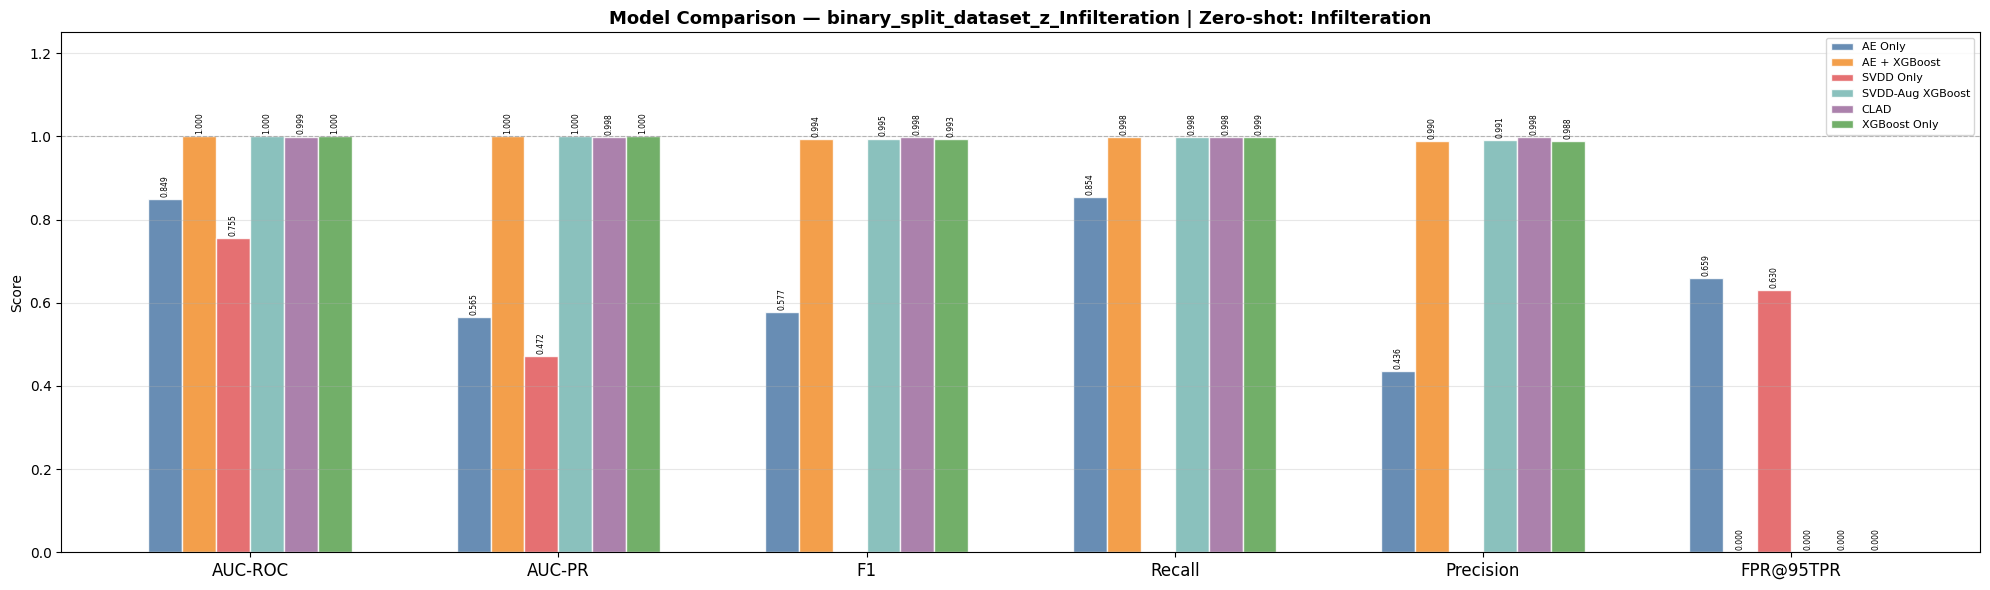

Saved: metric_comparison_bar_v1_infilteration.png


In [15]:
plot_metrics = [
    ('AUC-ROC',    'auc_roc'),
    ('AUC-PR',     'auc_pr'),
    ('F1',         'f1'),
    ('Recall',     'recall'),
    ('Precision',  'precision'),
    ('FPR@95TPR',  'fpr95'),
]

palette = ['#4e79a7', '#f28e2b', '#e15759', '#76b7b2', '#9c6b9e', '#59a14f', '#b07aa1']
x      = np.arange(len(plot_metrics))
width  = 0.11

fig, ax = plt.subplots(figsize=(20, 6))
for i, model in enumerate(model_order):
    vals = [results[model][key] if results[model][key] is not None else 0
            for _, key in plot_metrics]
    bars = ax.bar(x + i * width, vals, width, label=model,
                  color=palette[i % len(palette)], alpha=0.85, edgecolor='white')
    for bar, v in zip(bars, vals):
        if v > 0:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=5.5, rotation=90)

ax.set_xticks(x + width * (len(model_order)-1) / 2)
ax.set_xticklabels([l for l, _ in plot_metrics], fontsize=12)
ax.set_ylim(0, 1.25)
ax.set_ylabel('Score')
ax.set_title(f'Model Comparison — {DATA_DIR} | Zero-shot: {ZEROSHOT_LABEL}',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=8)
ax.grid(axis='y', alpha=0.3)
ax.axhline(1.0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.tight_layout()
plt.savefig(f'metric_comparison_bar{ARTIFACT_SUFFIX}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: metric_comparison_bar{ARTIFACT_SUFFIX}.png')

## CELL 15 — ROC Curves

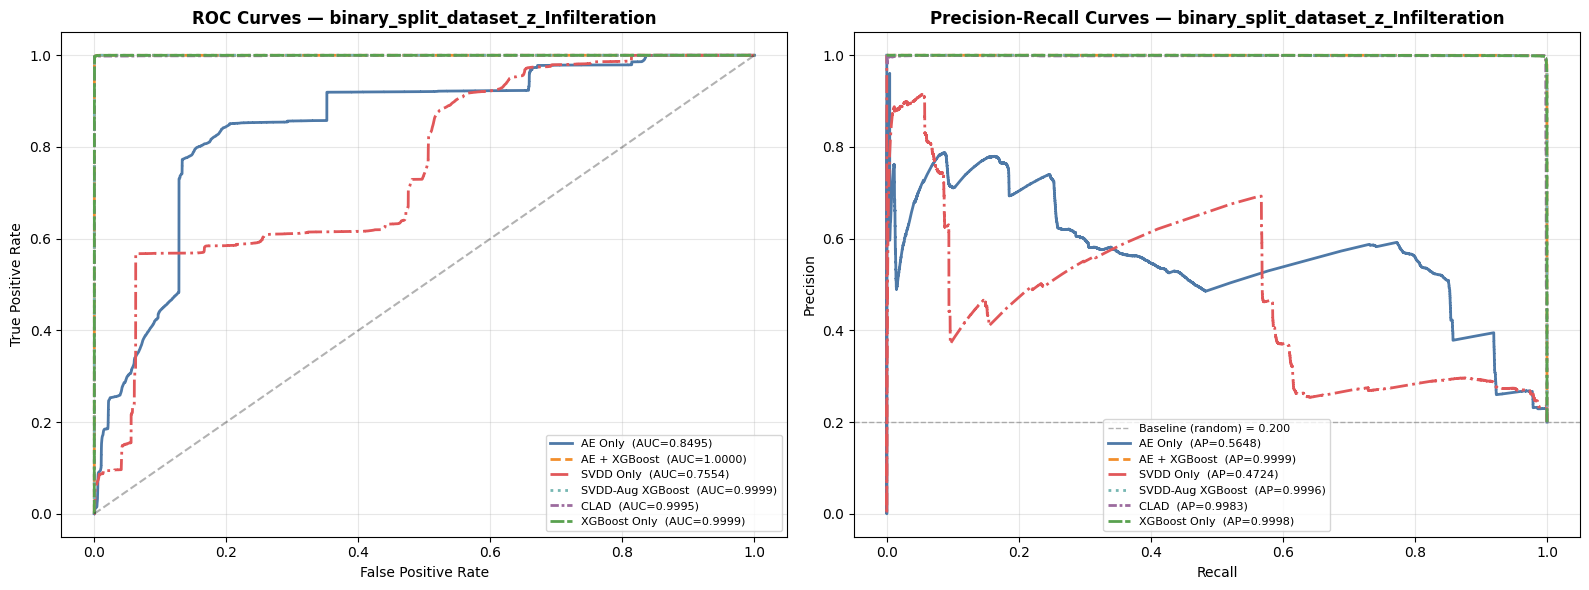

Saved: roc_pr_curves_v1_infilteration.png


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

palette   = ['#4e79a7', '#f28e2b', '#e15759', '#76b7b2', '#9c6b9e', '#59a14f', '#b07aa1']
linestyles = ['-', '--', '-.', ':', (0,(3,1,1,1)), (0,(5,1)), (0,(1,1))]

# ROC
ax = axes[0]
for i, (model, ls) in enumerate(zip(model_order, linestyles)):
    scores = results[model]['scores']
    if scores is None:
        continue
    fpr_c, tpr_c, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    ax.plot(fpr_c, tpr_c, linestyle=ls, linewidth=2, color=palette[i % len(palette)],
            label=f'{model}  (AUC={auc:.4f})')
ax.plot([0,1],[0,1],'k--', alpha=0.3)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title(f'ROC Curves — {DATA_DIR}', fontsize=12, fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# PR
ax = axes[1]
baseline_pr = y_test.mean()
ax.axhline(baseline_pr, color='gray', linestyle='--', linewidth=1,
           alpha=0.6, label=f'Baseline (random) = {baseline_pr:.3f}')
for i, (model, ls) in enumerate(zip(model_order, linestyles)):
    scores = results[model]['scores']
    if scores is None:
        continue
    prec_c, rec_c, _ = precision_recall_curve(y_test, scores)
    auc_pr = average_precision_score(y_test, scores)
    ax.plot(rec_c, prec_c, linestyle=ls, linewidth=2, color=palette[i % len(palette)],
            label=f'{model}  (AP={auc_pr:.4f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title(f'Precision-Recall Curves — {DATA_DIR}', fontsize=12, fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'roc_pr_curves{ARTIFACT_SUFFIX}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: roc_pr_curves{ARTIFACT_SUFFIX}.png')

## CELL 16 — Score Distributions (Test Set)

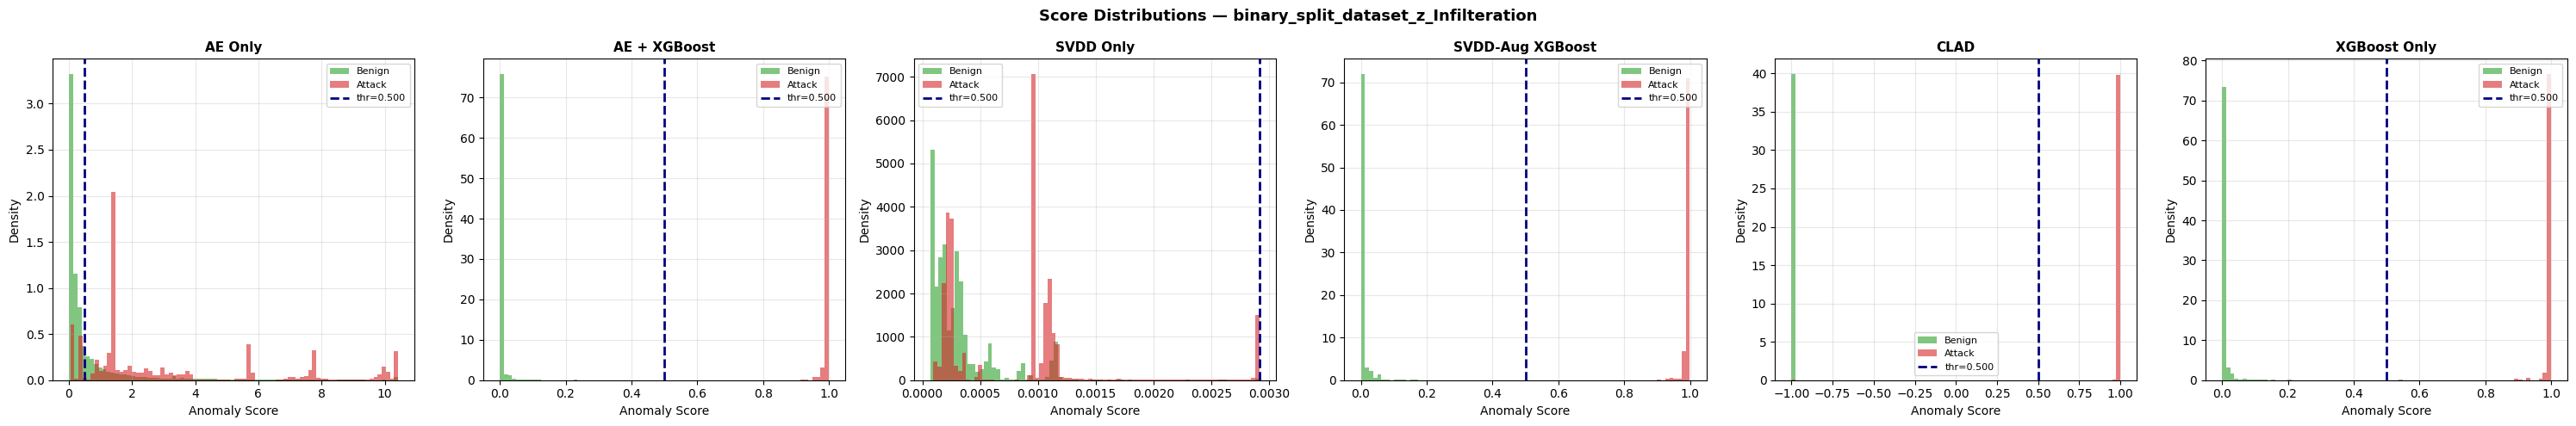

Saved: score_distributions_v1_infilteration.png


In [17]:
available = [(m, results[m]) for m in model_order if results[m]['scores'] is not None]
n_plots   = len(available)
fig, axes = plt.subplots(1, n_plots, figsize=(5 * n_plots, 5))
if n_plots == 1:
    axes = [axes]

for ax, (model, res) in zip(axes, available):
    scores = res['scores']
    thr    = res['threshold']
    clip_p = np.percentile(scores, 99)
    sc     = np.clip(scores, scores.min(), clip_p)
    ax.hist(sc[y_test==0], bins=80, alpha=0.6, color='#2ca02c', density=True, label='Benign')
    ax.hist(sc[y_test==1], bins=80, alpha=0.6, color='#d62728', density=True, label='Attack')
    if thr is not None:
        ax.axvline(min(thr, clip_p), color='navy', linestyle='--', linewidth=2,
                   label=f'thr={thr:.3f}')
    ax.set_title(model, fontsize=11, fontweight='bold')
    ax.set_xlabel('Anomaly Score'); ax.set_ylabel('Density')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle(f'Score Distributions — {DATA_DIR}', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'score_distributions{ARTIFACT_SUFFIX}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: score_distributions{ARTIFACT_SUFFIX}.png')

## CELL 17 — Confusion Matrices

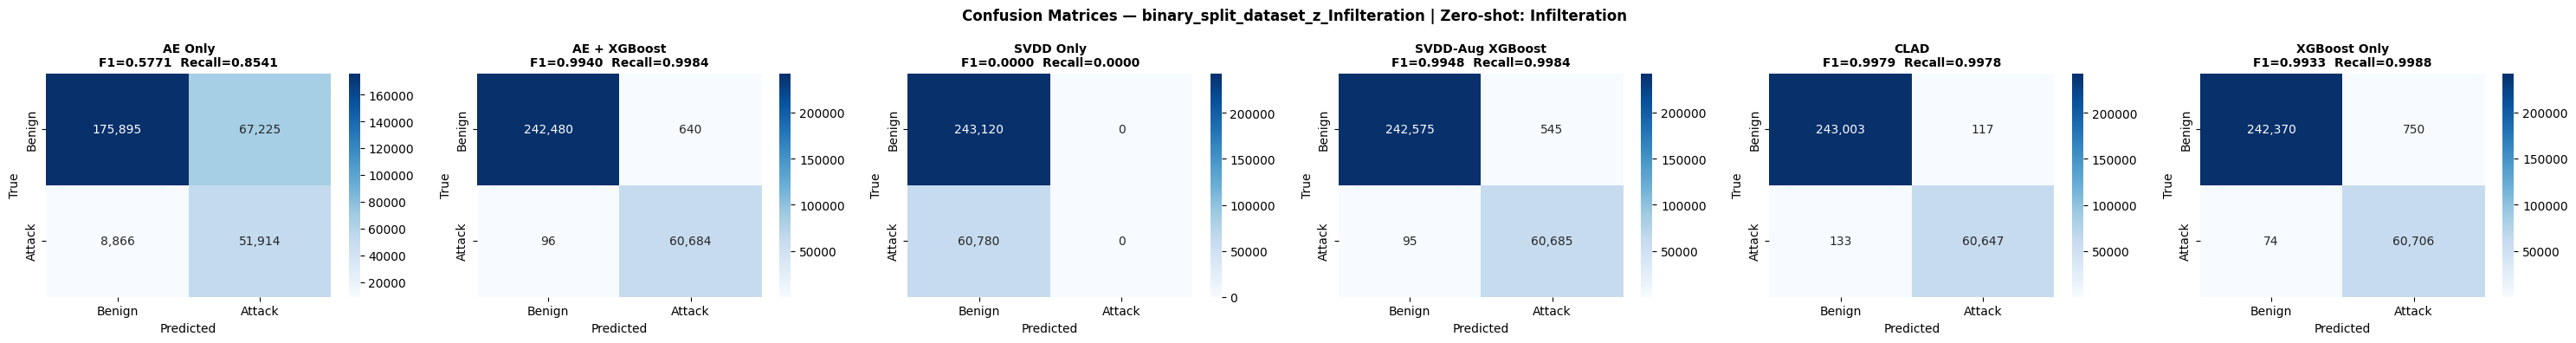

Saved: confusion_matrices_v1_infilteration.png


In [18]:
available_pred = [(m, results[m]) for m in model_order if results[m]['y_pred'] is not None]
n_plots = len(available_pred)
fig, axes = plt.subplots(1, n_plots, figsize=(5 * n_plots, 4))
if n_plots == 1:
    axes = [axes]

for ax, (model, res) in zip(axes, available_pred):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=ax,
                xticklabels=['Benign','Attack'], yticklabels=['Benign','Attack'])
    ax.set_title(f'{model}\nF1={res["f1"]:.4f}  Recall={res["recall"]:.4f}',
                 fontsize=10, fontweight='bold')
    ax.set_ylabel('True'); ax.set_xlabel('Predicted')

plt.suptitle(f'Confusion Matrices — {DATA_DIR} | Zero-shot: {ZEROSHOT_LABEL}',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'confusion_matrices{ARTIFACT_SUFFIX}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: confusion_matrices{ARTIFACT_SUFFIX}.png')

## CELL 18 — Zero-shot Detection

Zero-shot dataset: Infilteration (161,934 samples — ALL attack, unseen in training)

Model                          Detection Rate   Detected     Missed
----------------------------------------------------------------------
AE Only                                34.84%      56,424     105,510
AE + XGBoost                            0.78%       1,264     160,670
SVDD Only                               0.00%           0     161,934
SVDD-Aug XGBoost                        1.05%       1,704     160,230
CLAD                                    0.37%         594     161,340
XGBoost Only                            0.91%       1,468     160,466


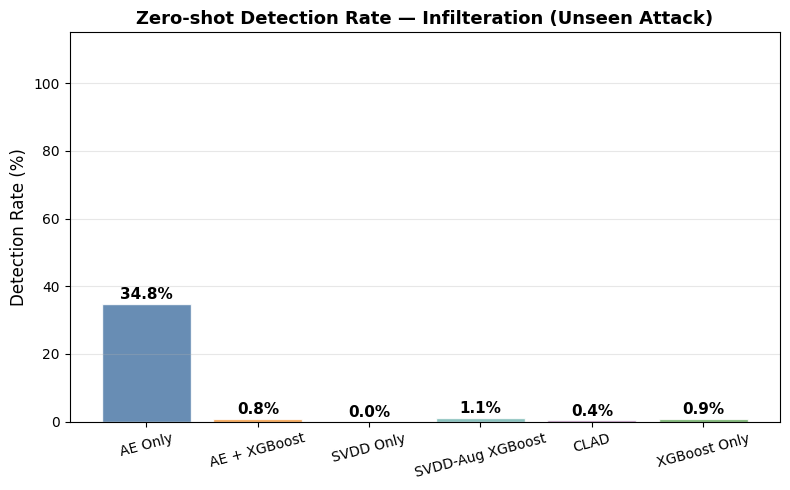

Saved: zero_shot_comparison_v1_infilteration.png


In [19]:
print(f"Zero-shot dataset: {ZEROSHOT_LABEL} ({len(y_zero):,} samples — ALL attack, unseen in training)")
print()
print(f"{'Model':<28} {'Detection Rate':>16} {'Detected':>10} {'Missed':>10}")
print('-'*70)
for model in model_order:
    zr = results[model]['zero_recall']
    if zr is None:
        print(f'{model:<28} {"N/A":>16}')
    else:
        detected = int(zr * len(y_zero))
        missed   = len(y_zero) - detected
        print(f'{model:<28} {zr*100:>15.2f}%  {detected:>10,}  {missed:>10,}')

# Bar chart
valid = [(m, results[m]['zero_recall']) for m in model_order
         if results[m]['zero_recall'] is not None]
if valid:
    models_z, rates_z = zip(*valid)
    colors_z = [palette[model_order.index(m) % len(palette)] for m in models_z]
    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(models_z, [r*100 for r in rates_z], color=colors_z, alpha=0.85, edgecolor='white')
    for bar, v in zip(bars, rates_z):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{v*100:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)
    ax.set_ylabel('Detection Rate (%)', fontsize=12)
    ax.set_title(f'Zero-shot Detection Rate — {ZEROSHOT_LABEL} (Unseen Attack)',
                 fontsize=13, fontweight='bold')
    ax.set_ylim(0, 115)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', labelrotation=15)
    plt.tight_layout()
    plt.savefig(f'zero_shot_comparison{ARTIFACT_SUFFIX}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: zero_shot_comparison{ARTIFACT_SUFFIX}.png')

## CELL 19 — Inference Latency Benchmark

Batch size: 1000 flows  |  Runs: 20

Model                                  Mean (ms)   Std (ms)   Max (ms)    ms/sample
----------------------------------------------------------------------------------
AE Only                                     6.18       0.80       7.75       0.0062
AE + XGBoost                               22.66       1.61      25.90       0.0227
SVDD Only                                  67.64      41.96     249.65       0.0676
SVDD-Aug XGBoost                           89.70      32.33     228.16       0.0897
CLAD                                       12.08       2.17      15.52       0.0121
XGBoost Only                                5.13       0.98       8.01       0.0051

→ TShark cycle = 10,000ms
  AE Only                             headroom = 9,994ms
  AE + XGBoost                        headroom = 9,977ms
  SVDD Only                           headroom = 9,932ms
  SVDD-Aug XGBoost                    headroom = 9,910ms
  CLAD                               

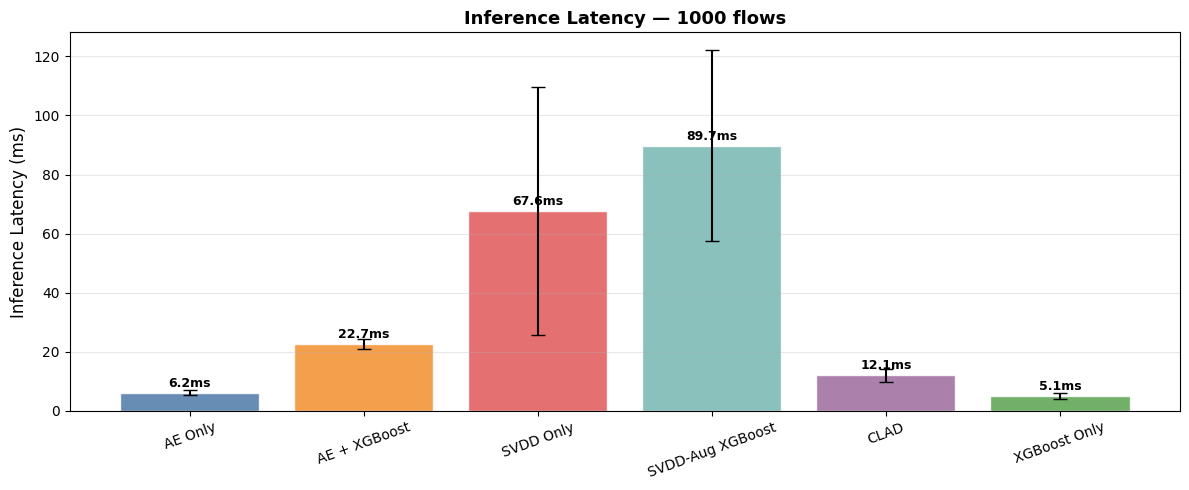

Saved: latency_comparison_v1_infilteration.png


In [20]:
BATCH_SIZE_BENCH = 1000
N_RUNS = 20
X_bench = X_test[:BATCH_SIZE_BENCH]

latency_results = {}

# ── AE only ─────────────────────────────────────────────────────
X_bench_ae = np.clip(ae_scaler.transform(X_bench), -CLIP_VAL, CLIP_VAL)
_ = get_ae_scores(ae_model, X_bench_ae)  # warm-up
times = []
for _ in range(N_RUNS):
    t0 = time.time(); get_ae_scores(ae_model, X_bench_ae); times.append(time.time()-t0)
latency_results['AE Only'] = np.array(times) * 1000

# ── AE + XGBoost ────────────────────────────────────────────────
times = []
for _ in range(N_RUNS):
    t0 = time.time()
    e = get_ae_scores(ae_model, X_bench_ae)
    z = get_ae_latent(ae_model, X_bench_ae)
    X_b_aug = np.concatenate([X_bench_ae, z, e.reshape(-1,1)], axis=1)
    xgb_aug.predict_proba(X_b_aug)
    times.append(time.time()-t0)
latency_results['AE + XGBoost'] = np.array(times) * 1000

# ── SVDD only ───────────────────────────────────────────────────
X_bench_svdd = np.clip(svdd_scaler.transform(X_bench), -CLIP_VAL, CLIP_VAL)
_ = svdd.decision_scores(X_bench_svdd)  # warm-up
times = []
for _ in range(N_RUNS):
    t0 = time.time(); svdd.decision_scores(X_bench_svdd); times.append(time.time()-t0)
latency_results['SVDD Only'] = np.array(times) * 1000

# ── SVDD-Aug XGBoost (K sphere distances + d_min as features) ──
if XGB_SVDD_AVAILABLE:
    times = []
    for _ in range(N_RUNS):
        t0 = time.time()
        d = svdd.all_sphere_distances(X_bench_svdd)
        X_b_aug_svdd = np.concatenate([X_bench_svdd, d, d.min(axis=1, keepdims=True)], axis=1)
        xgb_svdd.predict_proba(X_b_aug_svdd)
        times.append(time.time()-t0)
    latency_results['SVDD-Aug XGBoost'] = np.array(times) * 1000

# ── CLAD ────────────────────────────────────────────────────────
if CLAD_AVAILABLE:
    X_bench_clad = clad_norm.transform(X_bench.copy())
    bench_loader = DataLoader(
        NIDSDataset(X_bench_clad, np.zeros(len(X_bench_clad), dtype=int)),
        batch_size=1000, shuffle=False)
    _ = get_features(clad_model, bench_loader, DEVICE)  # warm-up
    times = []
    for _ in range(N_RUNS):
        t0 = time.time()
        z_b, _ = get_features(clad_model, bench_loader, DEVICE)
        -cosine_scores_to_centroid(z_b, centroid)
        times.append(time.time()-t0)
    latency_results['CLAD'] = np.array(times) * 1000

# ── XGBoost Only ────────────────────────────────────────────────
if 'XGBoost Only' in results:
    X_bench_xgb = np.clip(xgb_only_scaler.transform(X_bench), -CLIP_VAL, CLIP_VAL)
    _ = xgb_only.predict_proba(X_bench_xgb)  # warm-up
    times = []
    for _ in range(N_RUNS):
        t0 = time.time(); xgb_only.predict_proba(X_bench_xgb); times.append(time.time()-t0)
    latency_results['XGBoost Only'] = np.array(times) * 1000

# Print
print(f'Batch size: {BATCH_SIZE_BENCH} flows  |  Runs: {N_RUNS}')
print(f'\n{"Model":<35} {"Mean (ms)":>12} {"Std (ms)":>10} {"Max (ms)":>10} {"ms/sample":>12}')
print('-'*82)
for model, times_ms in latency_results.items():
    print(f'{model:<35} {times_ms.mean():>12.2f} {times_ms.std():>10.2f} '
          f'{times_ms.max():>10.2f} {times_ms.mean()/BATCH_SIZE_BENCH:>12.4f}')
print()
print(f'→ TShark cycle = 10,000ms')
for model, times_ms in latency_results.items():
    headroom = 10000 - times_ms.mean()
    print(f'  {model:<35} headroom = {headroom:,.0f}ms')

# Bar chart
fig, ax = plt.subplots(figsize=(12, 5))
models_lat = list(latency_results.keys())
means_lat  = [latency_results[m].mean() for m in models_lat]
stds_lat   = [latency_results[m].std()  for m in models_lat]
palette_ext = ['#4e79a7', '#f28e2b', '#e15759', '#76b7b2', '#9c6b9e', '#59a14f', '#b07aa1']
colors_lat = [palette_ext[model_order.index(m) % len(palette_ext)]
              if m in model_order else '#aec7e8' for m in models_lat]
ax.bar(models_lat, means_lat, yerr=stds_lat, color=colors_lat,
       alpha=0.85, edgecolor='white', capsize=5)
for i, (m, v) in enumerate(zip(models_lat, means_lat)):
    ax.text(i, v + 1, f'{v:.1f}ms', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_ylabel('Inference Latency (ms)', fontsize=12)
ax.set_title(f'Inference Latency — {BATCH_SIZE_BENCH} flows', fontsize=13, fontweight='bold')
ax.tick_params(axis='x', labelrotation=20)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'latency_comparison{ARTIFACT_SUFFIX}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: latency_comparison{ARTIFACT_SUFFIX}.png')

## CELL 20 — Final Summary (Styled DataFrame)

In [21]:
rows_final = []
for model in model_order:
    r = results[model]
    lat = latency_results.get(model)
    rows_final.append({
        'Model':            model,
        'AUC-ROC':          r['auc_roc'],
        'AUC-PR':           r['auc_pr'],
        'FPR@95TPR':        r['fpr95'],
        'F1':               r['f1'],
        'Recall':           r['recall'],
        'Precision':        r['precision'],
        'FPR':              r['fpr'],
        'Zero-shot Recall': r['zero_recall'],
        'Latency (ms)':     round(lat.mean(), 2) if lat is not None else None,
    })

df_final = pd.DataFrame(rows_final).set_index('Model')

# Highlight best per column
def highlight_best(s):
    numeric = pd.to_numeric(s, errors='coerce')
    if s.name in ('FPR@95TPR', 'FPR', 'Latency (ms)'):
        best = numeric.min()
    else:
        best = numeric.max()
    return ['font-weight: bold; color: #155724; background-color: #d4edda'
            if v == best else '' for v in numeric]

styled = (df_final
          .style
          .apply(highlight_best)
          .format(lambda x: f'{x:.4f}' if isinstance(x, float) else (str(x) if x is not None else 'N/A'))
          .set_caption(
              f'Model Comparison — {DATA_DIR} | Zero-shot: {ZEROSHOT_LABEL} (green = best per column)\n'
              f'SVDD-Aug XGBoost: K sphere distances + d_min as extra XGBoost input features'
          ))

display(styled)

# Also print plain text for easy copy-paste
print('\n--- Plain text ---')
print(df_final.to_string(float_format=lambda x: f'{x:.4f}'))

# Export to CSV (suffix theo dataset)
csv_path = f'comparison_results{ARTIFACT_SUFFIX}.csv'
df_final.to_csv(csv_path)
print(f'\nExported: {csv_path}')

,AUC-ROC,AUC-PR,FPR@95TPR,F1,Recall,Precision,FPR,Zero-shot Recall,Latency (ms)
Model,,,,,,,,,
AE Only,0.8495,0.5648,0.6589,0.5771,0.8541,0.4357,0.2765,0.3484,6.1800
AE + XGBoost,1.0000,0.9999,0.0001,0.9940,0.9984,0.9896,0.0026,0.0078,22.6600
SVDD Only,0.7554,0.4724,0.6298,0.0000,0.0000,0.0000,0.0000,0.0000,67.6400
SVDD-Aug XGBoost,0.9999,0.9996,0.0002,0.9948,0.9984,0.9911,0.0022,0.0105,89.7000
CLAD,0.9995,0.9983,0.0002,0.9979,0.9978,0.9981,0.0005,0.0037,12.0800
XGBoost Only,0.9999,0.9998,0.0002,0.9933,0.9988,0.9878,0.0031,0.0091,5.1300



--- Plain text ---
                  AUC-ROC  AUC-PR  FPR@95TPR     F1  Recall  Precision    FPR  Zero-shot Recall  Latency (ms)
Model                                                                                                        
AE Only            0.8495  0.5648     0.6589 0.5771  0.8541     0.4357 0.2765            0.3484        6.1800
AE + XGBoost       1.0000  0.9999     0.0001 0.9940  0.9984     0.9896 0.0026            0.0078       22.6600
SVDD Only          0.7554  0.4724     0.6298 0.0000  0.0000     0.0000 0.0000            0.0000       67.6400
SVDD-Aug XGBoost   0.9999  0.9996     0.0002 0.9948  0.9984     0.9911 0.0022            0.0105       89.7000
CLAD               0.9995  0.9983     0.0002 0.9979  0.9978     0.9981 0.0005            0.0037       12.0800
XGBoost Only       0.9999  0.9998     0.0002 0.9933  0.9988     0.9878 0.0031            0.0091        5.1300

Exported: comparison_results_v1_infilteration.csv
